# STDPの時定数と素材分類の正答率

保存済みの分類Excelを読み、全素材と素材ごとの正答率を時定数に対して表示します。学習や分類の再実行、図・集計結果の別ファイル保存は行いません。

- 各線はrep1〜5の平均、帯はrep間の標本標準偏差（±1 SD）です。
- 全素材の正答率：混同行列の対角成分の合計 ÷ 全試行数。
- 素材別の正答率：その素材の正解数 ÷ その素材の試行数（混同行列の行ごとの再現率）。
- 素材別も8素材分類の結果です。素材ごとに別の分類器を学習する処理ではありません。


In [4]:
from pathlib import Path
import sys
import posixpath
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

# LSM直下・h_analysis・その親から起動してもプロジェクトを見つける。
working_dir = Path.cwd().resolve()
project_candidates = [working_dir, *working_dir.parents, working_dir / "LSM"]
PROJECT_ROOT = next((p for p in project_candidates if (p / "a_experiment").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("LSMまたはh_analysisを作業フォルダにしてください。")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from d_tools.evaluation_excel import load_classification_results

# 読み込む保存済み実験・rep・評価ビン幅。必要な場合はここを変更する。
STDP_ROOT = PROJECT_ROOT / "g_tactile_results/readout_run/p_E_readout-0.11__g_e_out-0.2706/STDP"
REPS = list(range(1, 6))
TAUS_MS = list(range(5, 251, 5))
EVALUATION_BIN_MS = 25

# 日本語を表示できる、インストール済みのフォントを選ぶ。
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ("Yu Gothic", "Meiryo", "Noto Sans CJK JP", "MS Gothic"):
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
print(f"読み込み先：{STDP_ROOT}")


読み込み先：C:\Users\haru4\研究\研究コード\LSM\g_tactile_results\readout_run\p_E_readout-0.11__g_e_out-0.2706\STDP


In [5]:
def read_confusion_counts(workbook_path, materials):
    """既存の8素材混同行列を読み、素材の行・列順と個数を検証する。"""
    ns = {"s": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    with ZipFile(workbook_path) as archive:
        strings = []
        if "xl/sharedStrings.xml" in archive.namelist():
            strings = ["".join(node.itertext()) for node in ET.fromstring(archive.read("xl/sharedStrings.xml"))]
        relations = {node.attrib["Id"]: node.attrib["Target"] for node in ET.fromstring(archive.read("xl/_rels/workbook.xml.rels"))}
        workbook = ET.fromstring(archive.read("xl/workbook.xml"))
        sheet = next(node for node in workbook.findall("s:sheets/s:sheet", ns) if node.attrib["name"] == "conf_8cls")
        relation_id = sheet.attrib["{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id"]
        target = relations[relation_id]
        target = target.lstrip("/") if target.startswith("/") else posixpath.normpath(posixpath.join("xl", target))
        cells = {}
        for cell in ET.fromstring(archive.read(target)).findall("s:sheetData/s:row/s:c", ns):
            value = cell.find("s:v", ns)
            if cell.get("t") == "inlineStr":
                parsed = "".join(cell.find("s:is", ns).itertext())
            elif cell.get("t") == "s":
                parsed = strings[int(value.text)]
            elif cell.get("t") in ("str", "e"):
                parsed = value.text if value is not None else None
            elif value is not None:
                parsed = float(value.text)
            else:
                parsed = None
            cells[cell.attrib["r"]] = parsed
    columns = [chr(ord("B") + i) for i in range(len(materials))]
    if [cells[f"A{i+2}"] for i in range(len(materials))] != materials:
        raise ValueError(f"混同行列の行ラベルが素材順と一致しません：{workbook_path}")
    if [cells[f"{column}1"] for column in columns] != materials:
        raise ValueError(f"混同行列の列ラベルが素材順と一致しません：{workbook_path}")
    counts = np.array([[cells[f"{column}{i+2}"] for column in columns] for i in range(len(materials))], dtype=float)
    if not np.isfinite(counts).all() or np.any(counts < 0) or not np.equal(counts, np.floor(counts)).all() or np.any(counts.sum(axis=1) <= 0):
        raise ValueError(f"混同行列の個数が不正です：{workbook_path}")
    return counts

# 欠損を0%として扱わず、必要な結果が揃っていることを先に確認する。
workbooks = {(tau, rep): STDP_ROOT / f"tau_plus-{float(tau)}__tau_minus-{float(tau)}/rep{rep}/test/eval/classification.xlsx" for tau in TAUS_MS for rep in REPS}
missing = [str(path) for path in workbooks.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(f"分類結果が{len(missing)}件不足しています。先頭：{missing[0]}")

records = []
MATERIALS = None
reference_conditions = None
for (tau_ms, rep), workbook_path in workbooks.items():
    metadata = load_classification_results(workbook_path)
    if metadata is None or metadata.get("format_version") != 2:
        raise ValueError(f"対応する分類Excel形式ではありません：{workbook_path}")
    # 表示中の混同行列と評価ビン幅が必ず対応するよう、単一条件を確認する。
    if metadata["T_n_ms"] != [EVALUATION_BIN_MS] or len(metadata["summary"]) != 1:
        raise ValueError(f"評価ビン幅または評価条件が異なります：{workbook_path}")
    materials = metadata["materials"]
    conditions = (tuple(materials), metadata["folds"], metadata["base_seed"])
    if reference_conditions is None:
        reference_conditions = conditions
        MATERIALS = materials
    elif conditions != reference_conditions:
        raise ValueError(f"素材順・交差検証条件が異なります：{workbook_path}")
    counts = read_confusion_counts(workbook_path, materials)
    overall = np.trace(counts) / counts.sum()
    summary = metadata["summary"][0]
    if int(summary["rep"]) != rep or not np.isclose(overall, summary["accuracy"]):
        raise ValueError(f"正答率またはrepの整合性が取れません：{workbook_path}")
    records.append({"tau_ms": tau_ms, "rep": rep, "material": "All materials", "accuracy_pct": overall * 100})
    for material, correct, total in zip(materials, counts.diagonal(), counts.sum(axis=1)):
        records.append({"tau_ms": tau_ms, "rep": rep, "material": material, "accuracy_pct": correct / total * 100})

# 交差検証fold間のSDではなく、独立したrep間のSDを計算する。
accuracy_by_rep = pd.DataFrame(records)
accuracy_summary = (accuracy_by_rep.groupby(["material", "tau_ms"], sort=False)["accuracy_pct"]
                    .agg(mean_pct="mean", sd_pct="std", n_reps="count").reset_index())
print(f"読み込み完了：時定数{len(TAUS_MS)}条件 × {len(REPS)}rep = {len(workbooks)}ファイル")
print(f"評価：{EVALUATION_BIN_MS} msビン、{reference_conditions[1]}分割交差検証")


読み込み完了：時定数50条件 × 5rep = 250ファイル
評価：25 msビン、10分割交差検証


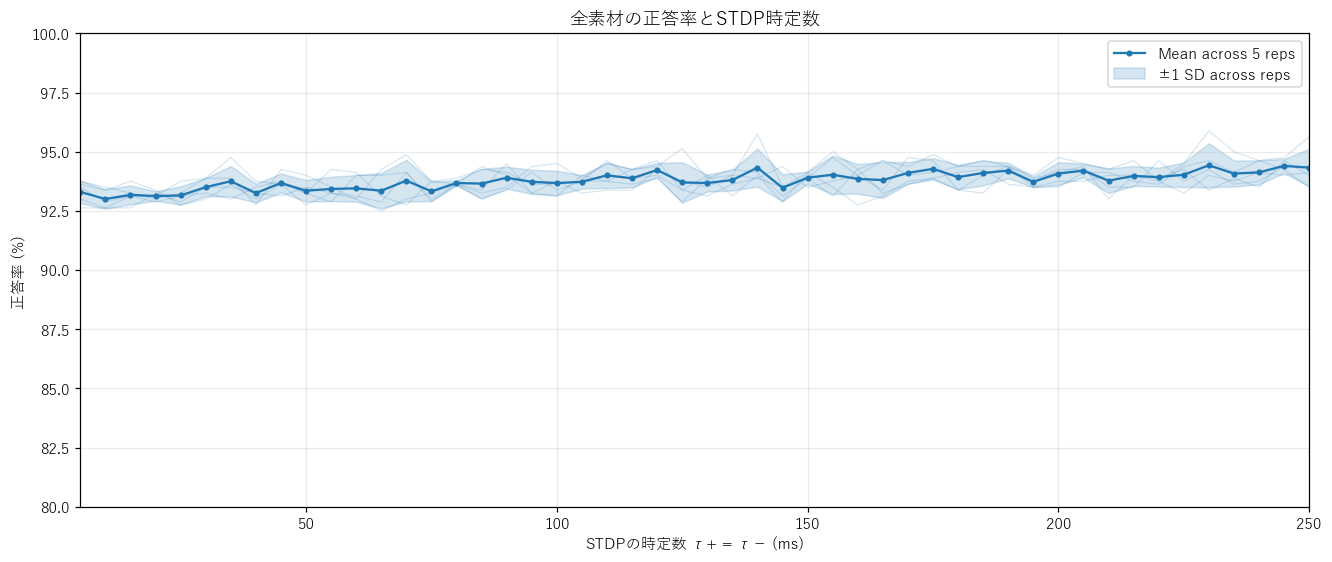

In [6]:
# 全素材をまとめた正答率。薄い線は各rep、太い線と帯は平均±SD。
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
for rep in REPS:
    selected = accuracy_by_rep.query("material == 'All materials' and rep == @rep").sort_values("tau_ms")
    ax.plot(selected["tau_ms"], selected["accuracy_pct"], color="tab:blue", alpha=0.18, linewidth=0.8)
selected = accuracy_summary.query("material == 'All materials'").sort_values("tau_ms")
x = selected["tau_ms"].to_numpy()
y = selected["mean_pct"].to_numpy()
sd = selected["sd_pct"].to_numpy()
ax.plot(x, y, "o-", color="tab:blue", markersize=3, label=f"Mean across {len(REPS)} reps")
ax.fill_between(x, y-sd, y+sd, color="tab:blue", alpha=0.18, label="±1 SD across reps")
ax.set(xlabel="STDPの時定数 τ+ = τ− (ms)", ylabel="正答率 (%)", title="全素材の正答率とSTDP時定数", xlim=(min(TAUS_MS), max(TAUS_MS)), ylim=(80, 100))
ax.grid(alpha=0.25)
ax.legend()
plt.show()


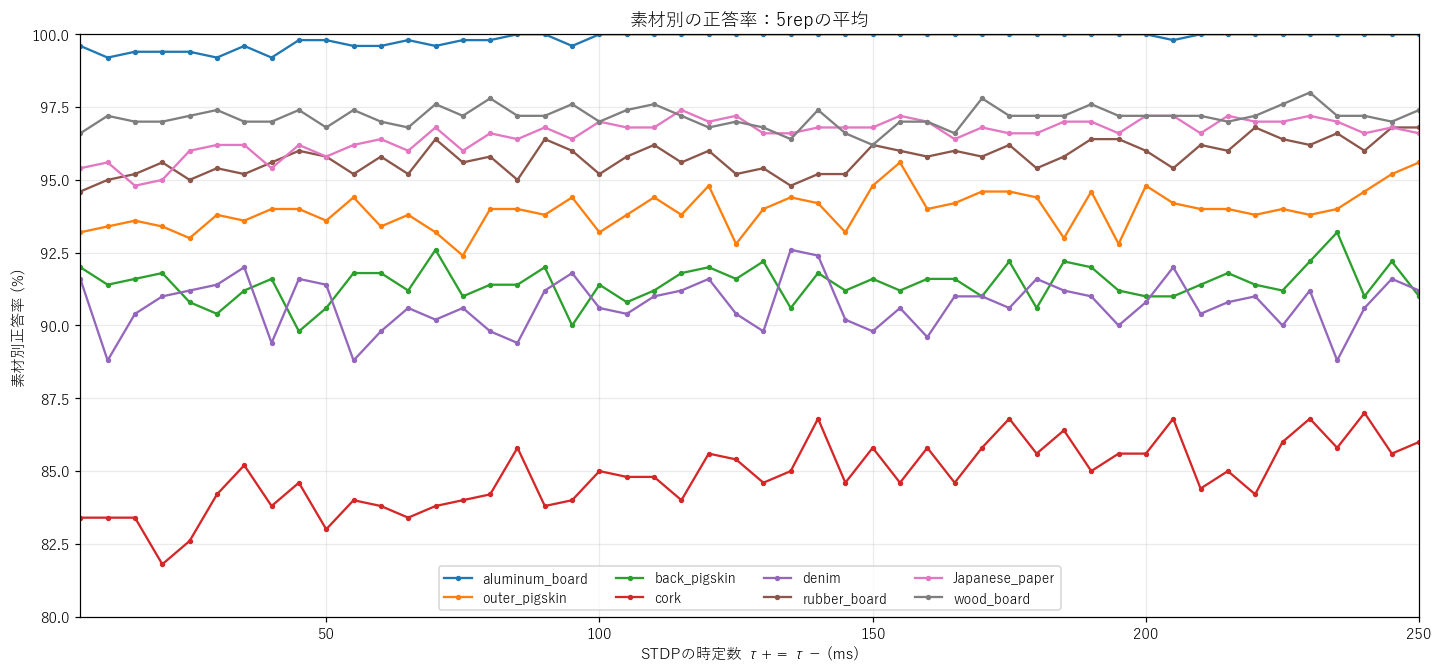

In [7]:
# 素材ごとの平均正答率を1つのグラフへ重ねて比較する。
fig, ax = plt.subplots(figsize=(13, 6), layout="constrained")
colors = plt.get_cmap("tab10").colors
for index, material in enumerate(MATERIALS):
    selected = accuracy_summary[accuracy_summary["material"] == material].sort_values("tau_ms")
    ax.plot(selected["tau_ms"], selected["mean_pct"], "o-", markersize=2.5, color=colors[index], label=material)
ax.set(xlabel="STDPの時定数 τ+ = τ− (ms)", ylabel="素材別正答率 (%)", title=f"素材別の正答率：{len(REPS)}repの平均", xlim=(min(TAUS_MS), max(TAUS_MS)), ylim=(80, 100))
ax.grid(alpha=0.25)
ax.legend(ncol=4, loc="lower center", fontsize=9)
plt.show()


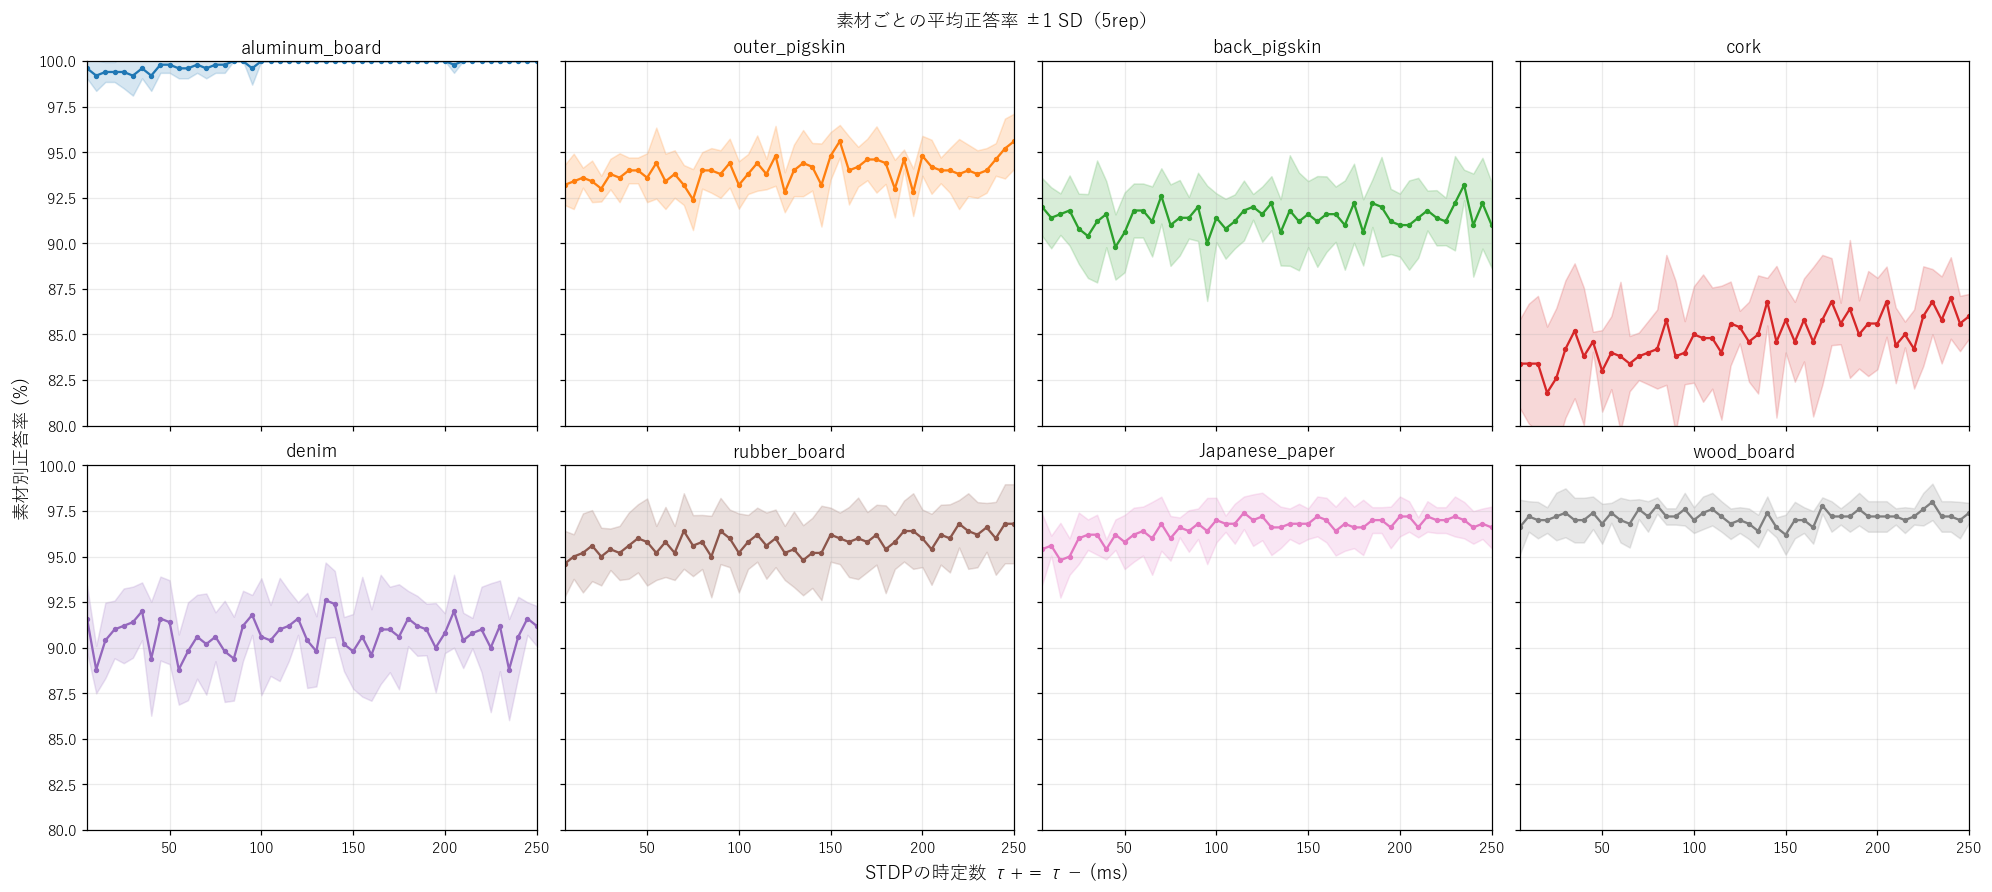

In [8]:
# 素材ごとに分け、rep間のばらつきも表示する。
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True, layout="constrained")
for index, (ax, material) in enumerate(zip(axes.flat, MATERIALS)):
    selected = accuracy_summary[accuracy_summary["material"] == material].sort_values("tau_ms")
    x = selected["tau_ms"].to_numpy()
    y = selected["mean_pct"].to_numpy()
    sd = selected["sd_pct"].to_numpy()
    ax.plot(x, y, "o-", color=colors[index], markersize=2.5)
    ax.fill_between(x, y-sd, y+sd, color=colors[index], alpha=0.18)
    ax.set(title=material, xlim=(min(TAUS_MS), max(TAUS_MS)), ylim=(80, 100))
    ax.grid(alpha=0.25)
fig.supxlabel("STDPの時定数 τ+ = τ− (ms)")
fig.supylabel("素材別正答率 (%)")
fig.suptitle(f"素材ごとの平均正答率 ±1 SD（{len(REPS)}rep）")
plt.show()


In [9]:
# 素材ごとに、rep平均の正答率が最も高い時定数を抽出する。
# 同率の場合は、時定数が最も小さい候補だけを表示する。
best_rows = []
for material in MATERIALS:
    selected = accuracy_summary[accuracy_summary["material"] == material].sort_values("tau_ms")
    highest_accuracy = selected["mean_pct"].max()
    winners = selected[np.isclose(selected["mean_pct"], highest_accuracy, rtol=0, atol=1e-10)]
    for row in winners.head(1).itertuples(index=False):
        best_rows.append({
            "素材": material,
            "最高正答率の時定数 (ms)": row.tau_ms,
            "平均正答率 (%)": row.mean_pct,
            "rep間の標準偏差 (%)": row.sd_pct,
            "rep数": row.n_reps,
        })
best_accuracy_by_material = pd.DataFrame(best_rows)
print("素材ごとの最高平均正答率（同率の場合は最小の時定数を表示）")
try:
    from IPython.display import display
except ImportError:
    print(best_accuracy_by_material.round(3).to_string(index=False))
else:
    display(best_accuracy_by_material.round(3))


素材ごとの最高平均正答率（同率の場合は最小の時定数を表示）


,素材,最高正答率の時定数 (ms),平均正答率 (%),rep間の標準偏差 (%),rep数
0,aluminum_board,85,100.0,0.000,5
1,outer_pigskin,155,95.6,0.894,5
2,back_pigskin,235,93.2,0.837,5
3,cork,240,87.0,2.236,5
4,denim,135,92.6,2.074,5
5,rubber_board,220,96.8,1.304,5
6,Japanese_paper,115,97.4,0.894,5
7,wood_board,230,98.0,1.000,5


## 素材別の最良時定数から10ニューロンずつ組み合わせる評価

各素材の最良時定数に対応する、保存済みの出力層80ニューロンから10個ずつ選び、合計80個の応答を連結して8素材分類します。**全試行で同じ80個を使い、正解素材に応じて入力を切り替えません。** ネットワークの再構築・再学習は行いません。

ランダム選択を各repで10回繰り返し、分類器と交差検証の分割方法は既存の評価に揃えます。表のSDは、10回の選択を平均した後のrep間SDです。

最良時定数の選択には、上で表示した同じ評価データの正答率を使っています。したがって、これは組み合わせを調べる探索的な結果であり、未使用データでの独立した性能評価ではありません。


       選択の基準素材  元の時定数 (ms)  選択ニューロン数
aluminum_board        85.0        10
 outer_pigskin       155.0        10
  back_pigskin       235.0        10
          cork       240.0        10
         denim       135.0        10
  rubber_board       220.0        10
Japanese_paper       115.0        10
    wood_board       230.0        10


Mixed readout evaluation:   0%|          | 0/5 [00:00<?, ?rep/s]

合計80ニューロン・25 msビン・10分割交差検証・PCA/標準化なし
各repで10回のランダム選択、合計50回の評価
                mean_pct  sd_pct  n_reps
material                                
All materials     93.788   0.382       5
aluminum_board   100.000   0.000       5
outer_pigskin     93.860   0.358       5
back_pigskin      91.260   1.913       5
cork              84.900   2.094       5
denim             90.260   1.861       5
rubber_board      96.000   1.729       5
Japanese_paper    96.920   0.550       5
wood_board        97.100   0.515       5


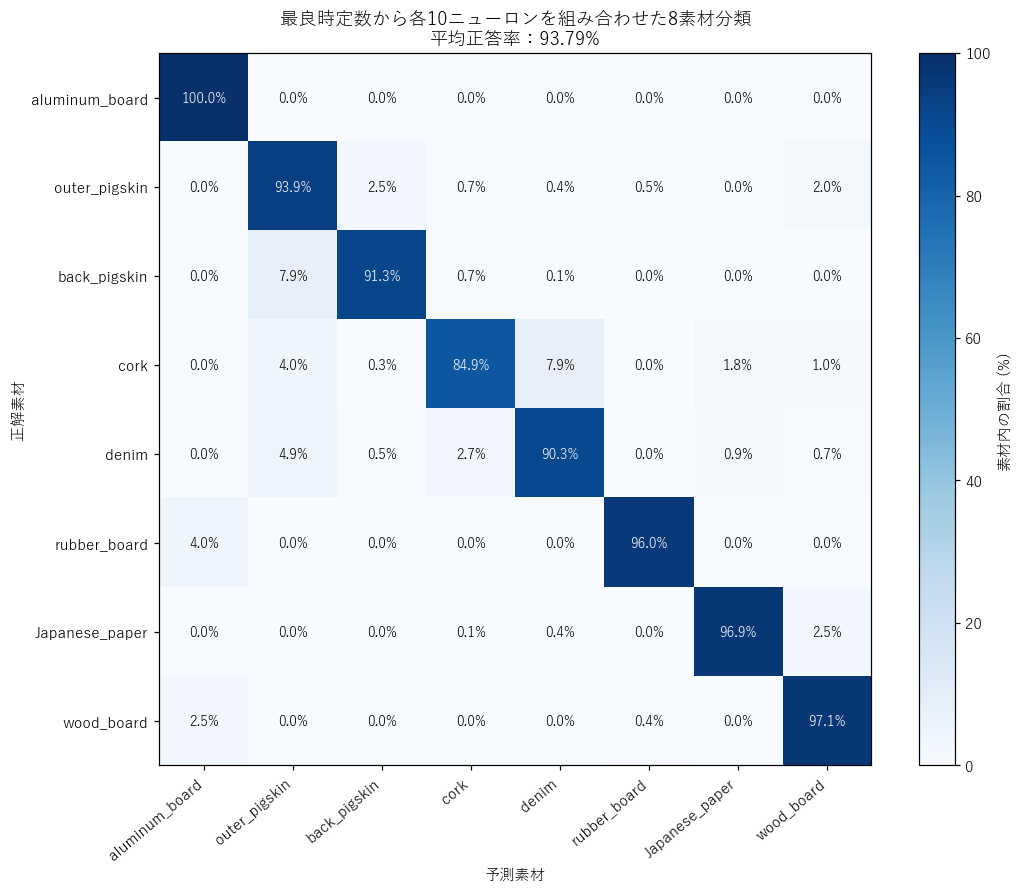

In [10]:
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
from d_tools.classification import classify
from d_tools.evaluation import extract_features, evaluate_classification
from d_tools.recording_io import read_record
from tqdm.auto import tqdm

# 各素材で最良だった時定数の層から10個ずつ取り、80個の特徴を作る。
NEURONS_PER_SOURCE = 10
RANDOM_SELECTIONS = 10
SELECTION_SEED = 20261031
best_tau_map = {row["素材"]: float(row["最高正答率の時定数 (ms)"]) for _, row in best_accuracy_by_material.iterrows()}
if len(best_tau_map) != len(MATERIALS):
    raise ValueError("先に素材ごとに1件の最良時定数を求めるセルを実行してください。")
source_table = pd.DataFrame([{"選択の基準素材": material, "元の時定数 (ms)": best_tau_map[material], "選択ニューロン数": NEURONS_PER_SOURCE} for material in MATERIALS])
print(source_table.to_string(index=False))

mixed_rows = []
selected_neuron_records = []
mixed_confusion = np.zeros((len(MATERIALS), len(MATERIALS)), dtype=np.int64)
with threadpool_limits(limits=1):
    for rep in tqdm(REPS, desc="Mixed readout evaluation", unit="rep"):
        source_features = {}
        reference_ids = None
        reference_shape = None
        for tau_ms in sorted(set(best_tau_map.values())):
            test_dir = STDP_ROOT / f"tau_plus-{tau_ms}__tau_minus-{tau_ms}/rep{rep}/test"
            metadata = read_record(test_dir / "test_config_snapshot.json")
            trial_ids = np.load(test_dir / f"test_trial_ids_rep{rep}.npy", allow_pickle=False)
            if metadata["materials"] != MATERIALS:
                raise ValueError(f"素材順が一致しません：{test_dir}")
            if reference_ids is None:
                reference_ids = trial_ids
            elif not np.array_equal(reference_ids, trial_ids):
                raise ValueError(f"時定数間で試行IDまたは試行順が違います：{test_dir}")
            # 1 ms記録を25 ms発火率へ集約してからニューロンを選ぶ。
            counts = np.load(test_dir / "rec/readout" / f"sout_rec_rep{rep}.npy", mmap_mode="r", allow_pickle=False)
            shape = counts.shape
            if len(shape) != 4 or shape[0] != len(MATERIALS) or shape[1] != len(trial_ids) or shape[2] < NEURONS_PER_SOURCE:
                raise ValueError(f"発火記録の形が不正です：{test_dir}")
            if reference_shape is None:
                reference_shape = shape
            elif shape != reference_shape:
                raise ValueError(f"時定数間で発火記録の形が違います：{test_dir}")
            features = extract_features(counts, EVALUATION_BIN_MS, bin_width_ms=metadata["recording_bin_width_ms"])
            time_bins = features.shape[-1] // shape[2]
            source_features[tau_ms] = features.reshape(shape[0] * shape[1], shape[2], time_bins)
            del counts
        labels = np.repeat(np.arange(len(MATERIALS)), reference_shape[1])
        splitter = StratifiedKFold(n_splits=int(reference_conditions[1]), shuffle=True, random_state=int(reference_conditions[2]) + rep - 1)
        folds = list(splitter.split(np.zeros(len(labels)), labels))
        for selection in range(1, RANDOM_SELECTIONS + 1):
            rng = np.random.default_rng(np.random.SeedSequence([SELECTION_SEED, rep, selection]))
            chosen_features = []
            used_ids = {tau: set() for tau in source_features}
            for material in MATERIALS:
                tau_ms = best_tau_map[material]
                available = np.array([i for i in range(source_features[tau_ms].shape[1]) if i not in used_ids[tau_ms]], dtype=int)
                if len(available) < NEURONS_PER_SOURCE:
                    raise ValueError("同じ時定数から重複なしに選べるニューロンが不足しています。")
                neuron_ids = np.sort(rng.choice(available, NEURONS_PER_SOURCE, replace=False))
                used_ids[tau_ms].update(neuron_ids.tolist())
                chosen_features.append(source_features[tau_ms][:, neuron_ids, :])
                selected_neuron_records.append({"rep": rep, "selection": selection, "material": material, "tau_ms": tau_ms, "neuron_ids": neuron_ids.tolist()})
            mixed_features = np.concatenate(chosen_features, axis=1).reshape(len(labels), -1)
            # 素材や評価foldによらず、各選択回で同じ80ニューロンを使用する。
            predictions = np.empty_like(labels)
            for train_indices, test_indices in folds:
                active = np.any(mixed_features[train_indices] != 0, axis=0)
                if not active.any():
                    raise ValueError("分類器の学習側に発火する特徴がありません。")
                predictions[test_indices] = classify(mixed_features[train_indices][:, active], labels[train_indices], mixed_features[test_indices][:, active])
            metrics = evaluate_classification(labels, predictions, labels=np.arange(len(MATERIALS)))
            mixed_confusion += metrics["confusion_matrix"]
            mixed_rows.append({"rep": rep, "selection": selection, "material": "All materials", "accuracy_pct": 100 * metrics["accuracy"]})
            for material, accuracy in zip(MATERIALS, metrics["per_class_accuracy"]):
                mixed_rows.append({"rep": rep, "selection": selection, "material": material, "accuracy_pct": 100 * accuracy})

# 10回の選択をrep内で平均し、その後に5repの平均とSDを求める。
mixed_accuracy_by_selection = pd.DataFrame(mixed_rows)
mixed_rep_means = mixed_accuracy_by_selection.groupby(["material", "rep"], as_index=False)["accuracy_pct"].mean()
mixed_accuracy_summary = mixed_rep_means.groupby("material")["accuracy_pct"].agg(mean_pct="mean", sd_pct="std", n_reps="count").reindex(["All materials", *MATERIALS])
print(f"合計{len(MATERIALS) * NEURONS_PER_SOURCE}ニューロン・{EVALUATION_BIN_MS} msビン・{reference_conditions[1]}分割交差検証・PCA/標準化なし")
print(f"各repで{RANDOM_SELECTIONS}回のランダム選択、合計{len(REPS) * RANDOM_SELECTIONS}回の評価")
print(mixed_accuracy_summary.round(3).to_string())

# 全rep・全ランダム選択の混同行列を行ごとの割合で表示する。
percentages = mixed_confusion / mixed_confusion.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
image = ax.imshow(percentages, vmin=0, vmax=100, cmap="Blues")
for i in range(len(MATERIALS)):
    for j in range(len(MATERIALS)):
        ax.text(j, i, f"{percentages[i, j]:.1f}%", ha="center", va="center", color="white" if percentages[i, j] > 50 else "black", fontsize=9)
ax.set(xticks=range(len(MATERIALS)), yticks=range(len(MATERIALS)), xticklabels=MATERIALS, yticklabels=MATERIALS,
       xlabel="予測素材", ylabel="正解素材", title=f"最良時定数から各10ニューロンを組み合わせた8素材分類\n平均正答率：{mixed_accuracy_summary.loc['All materials', 'mean_pct']:.2f}%")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.colorbar(image, ax=ax, label="素材内の割合 (%)")
plt.show()


## 同じrepのoffとSTDPを比較する

同じrep番号のoff（学習なし）の保存済み分類結果を読み込みます。STDPは全素材の平均正答率が最高だった時定数を使い、repごとの正答率と差を表示します。平均・標準偏差はrep間で計算します。分類の再実行や別ファイルへの保存は行いません。


同じrep・同じ試行・25 msビン・10分割交差検証
 rep  off正答率 (%)  STDP 230 ms正答率 (%)  STDP − off (ポイント)
   1      92.500              95.875              3.375
   2      92.500              94.250              1.750
   3      92.250              94.625              2.375
   4      92.625              93.375              0.750
   5      93.250              94.000              0.750

平均と標準偏差
        off正答率 (%)  STDP 230 ms正答率 (%)  STDP − off (ポイント)
rep平均       92.625              94.425               1.80
rep間SD       0.375               0.930               1.12


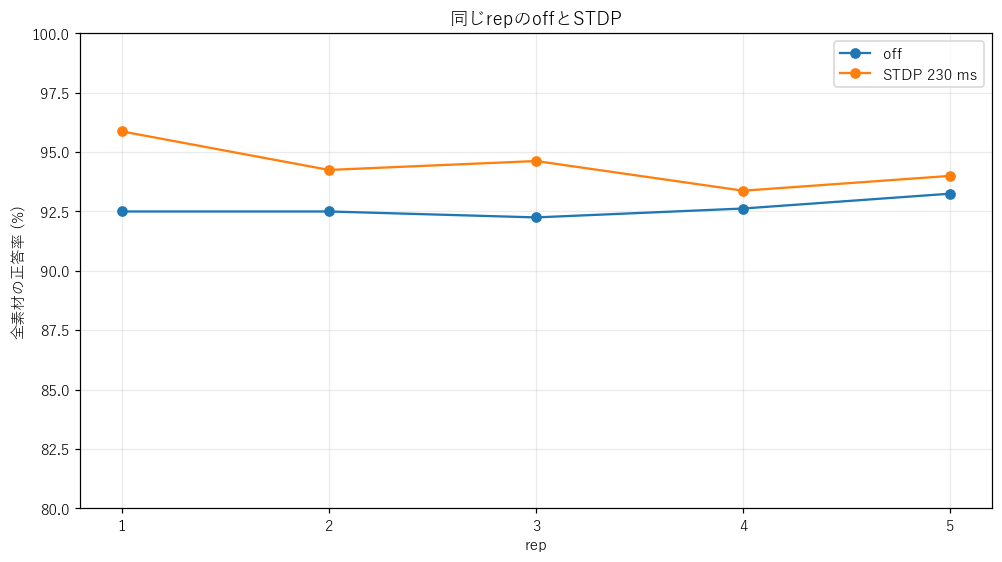

In [11]:
# STDPと同じrep番号・25 msビン・交差検証条件のoff結果を読む。
OFF_ROOT = STDP_ROOT.parent / "off"
overall_stdp = accuracy_summary[accuracy_summary["material"] == "All materials"].sort_values("tau_ms")
maximum_stdp = overall_stdp["mean_pct"].max()
# STDPの最高平均が同率なら、最小の時定数を比較対象にする。
best_overall_tau = float(overall_stdp.loc[np.isclose(overall_stdp["mean_pct"], maximum_stdp, rtol=0, atol=1e-10), "tau_ms"].iloc[0])
off_comparison_rows = []
for rep in REPS:
    workbook_path = OFF_ROOT / f"rep{rep}/test/eval/classification.xlsx"
    if not workbook_path.is_file():
        raise FileNotFoundError(f"offの分類結果がありません：{workbook_path}")
    metadata = load_classification_results(workbook_path)
    if metadata is None or metadata.get("format_version") != 2:
        raise ValueError(f"対応する分類Excel形式ではありません：{workbook_path}")
    conditions = (tuple(metadata["materials"]), metadata["folds"], metadata["base_seed"])
    if conditions != reference_conditions or metadata["T_n_ms"] != [EVALUATION_BIN_MS] or len(metadata["summary"]) != 1:
        raise ValueError(f"offとSTDPで評価条件が異なります：{workbook_path}")
    counts = read_confusion_counts(workbook_path, MATERIALS)
    off_accuracy = np.trace(counts) / counts.sum() * 100
    summary = metadata["summary"][0]
    if int(summary["rep"]) != rep or not np.isclose(off_accuracy, float(summary["accuracy"]) * 100):
        raise ValueError(f"offのrepまたは正答率に不整合があります：{workbook_path}")
    # 同じrepで提示試行と試行順が一致していることを照合する。
    off_ids = np.load(OFF_ROOT / f"rep{rep}/test/test_trial_ids_rep{rep}.npy", allow_pickle=False)
    stdp_test = STDP_ROOT / f"tau_plus-{best_overall_tau}__tau_minus-{best_overall_tau}/rep{rep}/test"
    stdp_ids = np.load(stdp_test / f"test_trial_ids_rep{rep}.npy", allow_pickle=False)
    if not np.array_equal(off_ids, stdp_ids):
        raise ValueError(f"offとSTDPの試行IDまたは提示順が異なります：rep{rep}")
    stdp_accuracy = accuracy_by_rep.loc[(accuracy_by_rep["material"] == "All materials") & (accuracy_by_rep["rep"] == rep) & (accuracy_by_rep["tau_ms"] == best_overall_tau), "accuracy_pct"].item()
    off_comparison_rows.append({"rep": rep, "off正答率 (%)": off_accuracy, f"STDP {best_overall_tau:g} ms正答率 (%)": stdp_accuracy, "STDP − off (ポイント)": stdp_accuracy - off_accuracy})
off_rep_comparison = pd.DataFrame(off_comparison_rows)
score_columns = [column for column in off_rep_comparison.columns if column != "rep"]
off_comparison_summary = off_rep_comparison[score_columns].agg(["mean", "std"]).rename(index={"mean": "rep平均", "std": "rep間SD"})
print(f"同じrep・同じ試行・{EVALUATION_BIN_MS} msビン・{reference_conditions[1]}分割交差検証")
print(off_rep_comparison.round(3).to_string(index=False))
print("\n平均と標準偏差")
print(off_comparison_summary.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.plot(off_rep_comparison["rep"], off_rep_comparison["off正答率 (%)"], "o-", label="off")
stdp_column = f"STDP {best_overall_tau:g} ms正答率 (%)"
ax.plot(off_rep_comparison["rep"], off_rep_comparison[stdp_column], "o-", label=f"STDP {best_overall_tau:g} ms")
ax.set(xlabel="rep", ylabel="全素材の正答率 (%)", title="同じrepのoffとSTDP", xticks=REPS, ylim=(80, 100))
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## STDP・230 ms：評価に使うニューロンを5個ずつ減らす

保存済みのSTDP・230 msの出力応答を使い、80→75→70→…→5ニューロンへ減らして8素材分類します。学習済みネットワークは変更せず、分類器へ渡すニューロンだけを選択します。

各repでランダムな削減順を10通り作り、同じ順序の中ではニューロン集合が入れ子になるように減らします。選択したニューロンは全素材・全foldで共通です。25 msビン・同じ10分割交差検証を使い、PCA・標準化は行いません。

線はrep内で10通りを平均した後のrep平均、帯はそのrep間SDです。少数ニューロンで80%を下回る場合も見えるよう、このグラフの縦軸は0〜100%にしています。時定数230 msは上の評価結果で選んだため、探索的な比較として扱います。


230 ms neuron reduction:   0%|          | 0/5 [00:00<?, ?rep/s]

rep1: removal orders:   0%|          | 0/10 [00:00<?, ?it/s]

rep2: removal orders:   0%|          | 0/10 [00:00<?, ?it/s]

rep3: removal orders:   0%|          | 0/10 [00:00<?, ?it/s]

rep4: removal orders:   0%|          | 0/10 [00:00<?, ?it/s]

rep5: removal orders:   0%|          | 0/10 [00:00<?, ?it/s]

STDP 230 ms：80個から5個まで5個刻み。各rep10通りの削減順。
           mean_pct  sd_pct  min_rep_pct  max_rep_pct  n_reps
n_neurons                                                    
80           94.425   0.930       93.375       95.875       5
75           94.410   0.755       93.562       95.575       5
70           94.360   0.635       93.688       95.338       5
65           94.225   0.597       93.438       95.050       5
60           94.092   0.492       93.488       94.800       5
55           93.872   0.452       93.412       94.562       5
50           93.602   0.488       93.175       94.338       5
45           93.417   0.528       92.775       94.062       5
40           93.138   0.496       92.600       93.700       5
35           92.488   0.558       91.712       93.075       5
30           91.980   0.492       91.438       92.600       5
25           90.778   0.671       89.975       91.462       5
20           88.890   0.970       87.925       90.025       5
15           85.940   0.815   

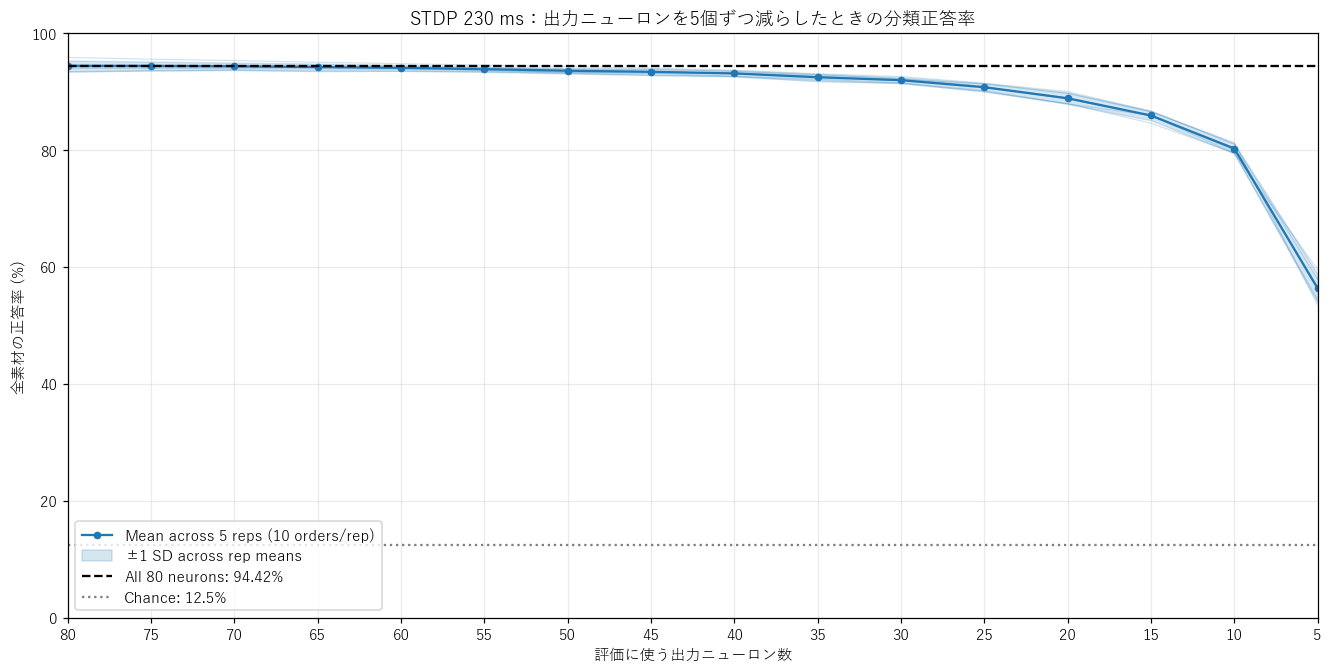

In [12]:
# このセルは最初の設定・結果読み込みセルの実行後に単独でも実行できる。
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
from d_tools.classification import classify
from d_tools.evaluation import extract_features, evaluate_classification
from d_tools.recording_io import read_record
from tqdm.auto import tqdm

REDUCTION_TAU_MS = 230.0
RETAINED_NEURON_COUNTS = list(range(80, 0, -5))
REMOVAL_ORDERS = 10
REMOVAL_SEED = 20261031
reduction_rows = []
removal_order_records = []
with threadpool_limits(limits=1):
    for rep in tqdm(REPS, desc="230 ms neuron reduction", unit="rep"):
        test_dir = STDP_ROOT / f"tau_plus-{REDUCTION_TAU_MS}__tau_minus-{REDUCTION_TAU_MS}/rep{rep}/test"
        metadata = read_record(test_dir / "test_config_snapshot.json")
        counts = np.load(test_dir / "rec/readout" / f"sout_rec_rep{rep}.npy", mmap_mode="r", allow_pickle=False)
        if metadata["materials"] != MATERIALS or counts.ndim != 4 or counts.shape[2] != 80:
            raise ValueError(f"素材順または出力ニューロン数が想定と異なります：{test_dir}")
        features = extract_features(counts, EVALUATION_BIN_MS, bin_width_ms=metadata["recording_bin_width_ms"])
        n_materials, n_trials = counts.shape[:2]
        time_bins = features.shape[-1] // 80
        features = features.reshape(n_materials * n_trials, 80, time_bins)
        del counts
        labels = np.repeat(np.arange(n_materials), n_trials)
        splitter = StratifiedKFold(n_splits=int(reference_conditions[1]), shuffle=True, random_state=int(reference_conditions[2]) + rep - 1)
        folds = list(splitter.split(np.zeros(len(labels)), labels))
        full_metrics = None
        for order_index in tqdm(range(1, REMOVAL_ORDERS + 1), desc=f"rep{rep}: removal orders", leave=False):
            rng = np.random.default_rng(np.random.SeedSequence([REMOVAL_SEED, rep, order_index]))
            neuron_order = rng.permutation(80)
            removal_order_records.append({"rep": rep, "order": order_index, "neuron_order": neuron_order.tolist()})
            for retained in RETAINED_NEURON_COUNTS:
                # 全80個の評価は各rep1回だけ計算し、同じ結果を10通りへ使用する。
                if retained == 80 and full_metrics is not None:
                    metrics = full_metrics
                else:
                    neuron_ids = np.sort(neuron_order[:retained])
                    selected = features[:, neuron_ids, :].reshape(len(labels), -1)
                    predictions = np.empty_like(labels)
                    for train_indices, test_indices in folds:
                        active = np.any(selected[train_indices] != 0, axis=0)
                        if not active.any():
                            raise ValueError(f"分類器の学習側に発火する特徴がありません：rep{rep}, {retained} neurons")
                        predictions[test_indices] = classify(selected[train_indices][:, active], labels[train_indices], selected[test_indices][:, active])
                    metrics = evaluate_classification(labels, predictions, labels=np.arange(n_materials))
                    if retained == 80:
                        full_metrics = metrics
                        expected = accuracy_by_rep.loc[(accuracy_by_rep["material"] == "All materials") & (accuracy_by_rep["rep"] == rep) & (accuracy_by_rep["tau_ms"] == REDUCTION_TAU_MS), "accuracy_pct"].item()
                        if not np.isclose(metrics["accuracy"] * 100, expected):
                            raise ValueError(f"全80個の再評価が保存済み正答率と一致しません：rep{rep}")
                reduction_rows.append({"rep": rep, "order": order_index, "n_neurons": retained, "accuracy_pct": metrics["accuracy"] * 100})

# ランダム選択10通りをrep内で平均し、その後にrep間の平均とSDを求める。
reduction_by_selection = pd.DataFrame(reduction_rows)
reduction_rep_means = reduction_by_selection.groupby(["n_neurons", "rep"], as_index=False)["accuracy_pct"].mean()
reduction_summary = (reduction_rep_means.groupby("n_neurons")["accuracy_pct"]
                     .agg(mean_pct="mean", sd_pct="std", min_rep_pct="min", max_rep_pct="max", n_reps="count")
                     .reindex(RETAINED_NEURON_COUNTS))
print("STDP 230 ms：80個から5個まで5個刻み。各rep10通りの削減順。")
print(reduction_summary.round(3).to_string())

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
for rep in REPS:
    selected = reduction_rep_means[reduction_rep_means["rep"] == rep].set_index("n_neurons").reindex(RETAINED_NEURON_COUNTS)
    ax.plot(selected.index, selected["accuracy_pct"], color="tab:blue", alpha=0.2, linewidth=0.8)
x = reduction_summary.index.to_numpy()
y = reduction_summary["mean_pct"].to_numpy()
sd = reduction_summary["sd_pct"].to_numpy()
ax.plot(x, y, "o-", color="tab:blue", markersize=4, label=f"Mean across {len(REPS)} reps (10 orders/rep)")
ax.fill_between(x, y-sd, y+sd, color="tab:blue", alpha=0.18, label="±1 SD across rep means")
ax.axhline(reduction_summary.loc[80, "mean_pct"], color="black", linestyle="--", label=f"All 80 neurons: {reduction_summary.loc[80, 'mean_pct']:.2f}%")
ax.axhline(100 / len(MATERIALS), color="gray", linestyle=":", label=f"Chance: {100 / len(MATERIALS):.1f}%")
ax.set(xlabel="評価に使う出力ニューロン数", ylabel="全素材の正答率 (%)", title="STDP 230 ms：出力ニューロンを5個ずつ減らしたときの分類正答率", xlim=(80, 5), ylim=(0, 100), xticks=RETAINED_NEURON_COUNTS)
ax.grid(alpha=0.25)
ax.legend(loc="lower left")
plt.show()


## STDP・230 msの出力層PCA

`PCA_REP`で指定したrepの全80ニューロン・全評価試行を、25 msビンの発火率に集約してPCAで可視化します。初期値はrep1です。

1試行は80ニューロン×20ビン＝1,600特徴。特徴ごとの平均だけを引き、標準化は行いません。PC1〜PC3の3次元散布図、2次元散布図3組、PC1〜PC40の累積寄与率を表示します。

各repの出力は異なるニューロンなので、repを混ぜず個別にPCAを計算します。ここでは評価応答全体の構造を見るため全試行でPCAを当てはめており、分類精度を測る学習・評価分割とは別の可視化です。


STDP 230 ms / rep2 / 8素材×100試行 / 全80ニューロン
25 ms×20ビン、1試行1600特徴、平均中心化のみ（標準化なし）
PC1〜PC3の寄与率：79.57%, 3.87%, 0.96%
PC1〜PC40の累積寄与率：88.78%


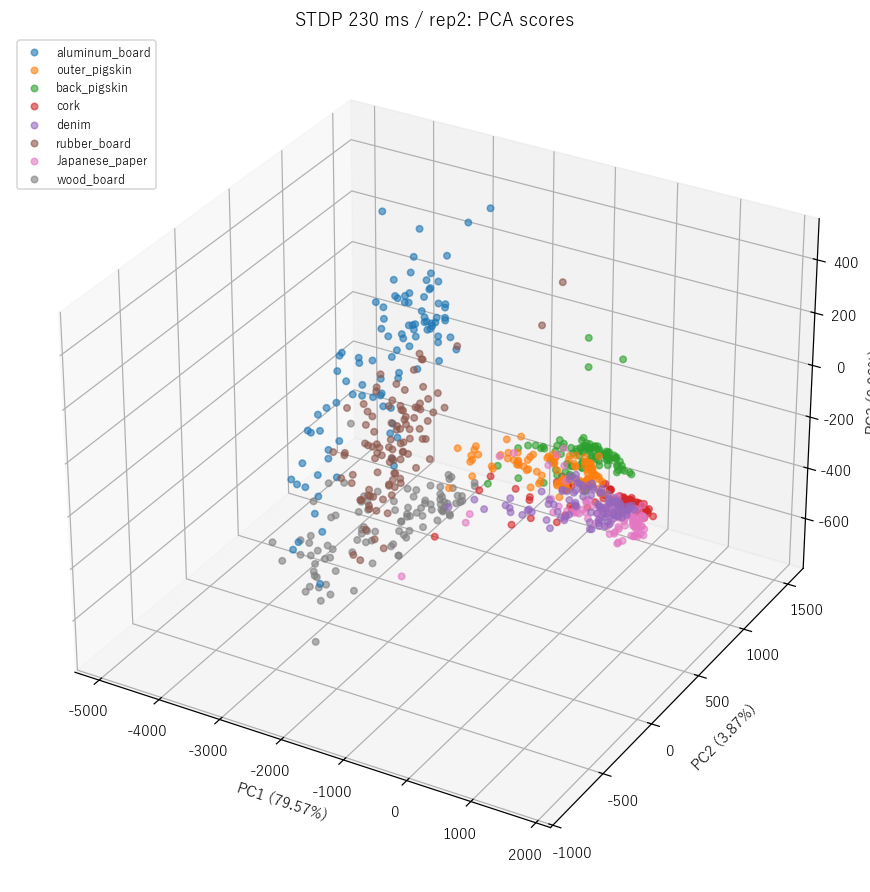

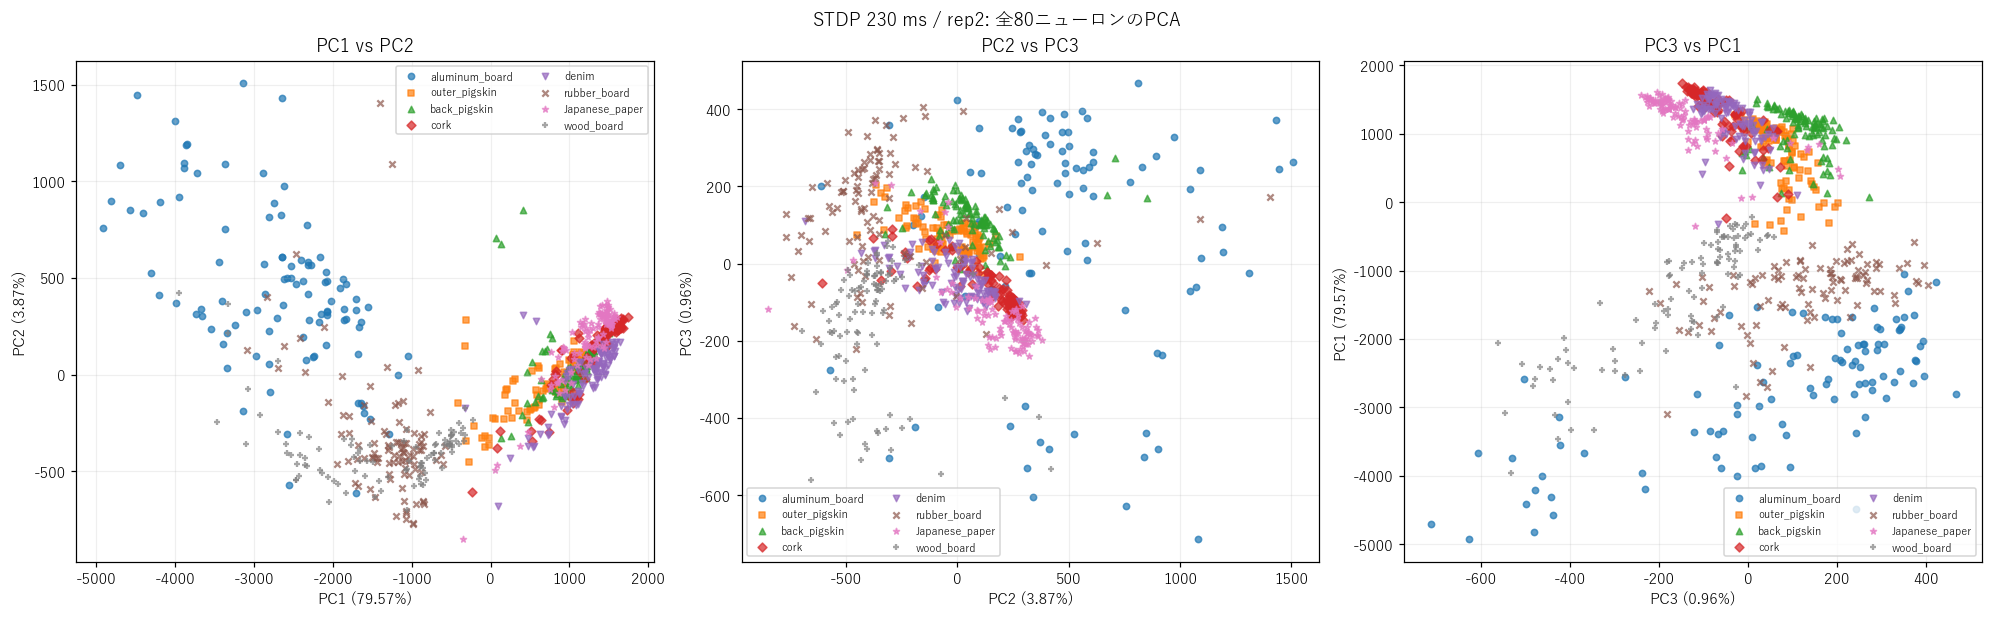

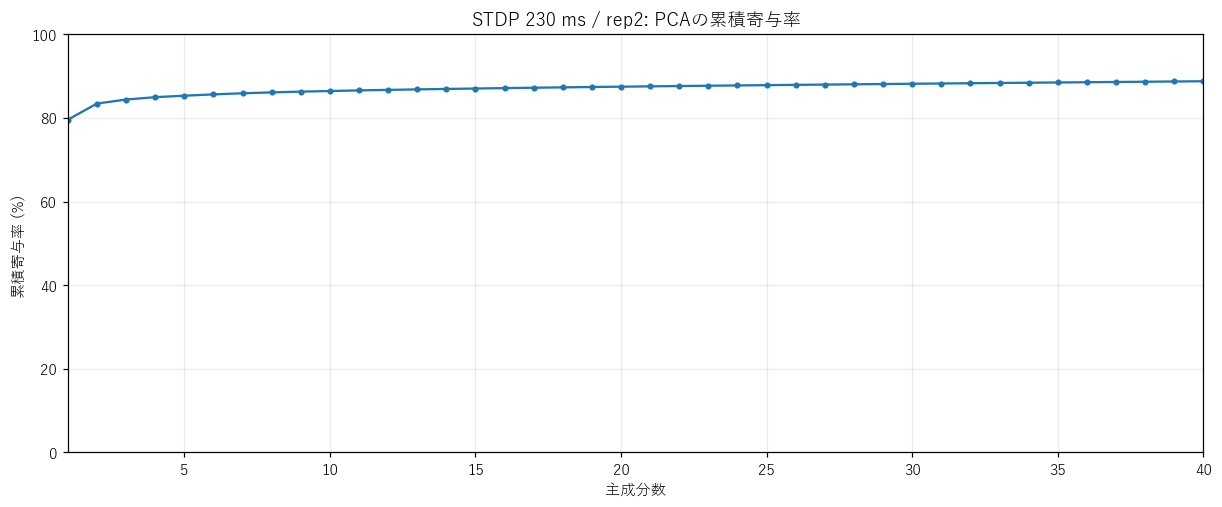

In [13]:
from d_tools.pca import fit_transform_pca
from d_tools.evaluation import extract_features
from d_tools.recording_io import read_record
from threadpoolctl import threadpool_limits

# repを変更する場合はここを指定して、このセルを再実行する。
PCA_REP = 2
PCA_TAU_MS = 230.0
PCA_COMPONENTS = 40
pca_test_dir = STDP_ROOT / f"tau_plus-{PCA_TAU_MS}__tau_minus-{PCA_TAU_MS}/rep{PCA_REP}/test"
pca_metadata = read_record(pca_test_dir / "test_config_snapshot.json")
pca_materials = list(pca_metadata["materials"])
pca_counts = np.load(pca_test_dir / "rec/readout" / f"sout_rec_rep{PCA_REP}.npy", mmap_mode="r", allow_pickle=False)
if pca_counts.ndim != 4 or pca_counts.shape[0] != len(pca_materials) or pca_counts.shape[2] != 80:
    raise ValueError("素材×試行×80ニューロン×時間の発火記録が必要です。")
n_materials, n_trials, n_neurons = pca_counts.shape[:3]
pca_features = extract_features(pca_counts, EVALUATION_BIN_MS, bin_width_ms=pca_metadata["recording_bin_width_ms"])
pca_time_bins = pca_features.shape[-1] // n_neurons
pca_states = pca_features.reshape(n_materials * n_trials, n_neurons, pca_time_bins)
pca_labels = np.repeat(np.arange(n_materials), n_trials)
# PCAツールは標準化を行わず、各ニューロン・各時間ビンの平均だけを差し引く。
with threadpool_limits(limits=1):
    pca_scores, pca_model = fit_transform_pca(pca_states, n_components=PCA_COMPONENTS)
if pca_model.total_variance is None or pca_model.total_variance <= 0:
    raise ValueError("PCAで説明する分散がありません。")
pca_variance_pct = pca_model.explained_variance / pca_model.total_variance * 100
pca_cumulative_pct = np.cumsum(pca_variance_pct)
pca_colors = plt.get_cmap("tab10").colors
pca_markers = ["o", "s", "^", "D", "v", "x", "*", "+"]
print(f"STDP {PCA_TAU_MS:g} ms / rep{PCA_REP} / {n_materials}素材×{n_trials}試行 / 全{n_neurons}ニューロン")
print(f"{EVALUATION_BIN_MS} ms×{pca_time_bins}ビン、1試行{n_neurons * pca_time_bins}特徴、平均中心化のみ（標準化なし）")
print("PC1〜PC3の寄与率：" + ", ".join(f"{value:.2f}%" for value in pca_variance_pct[:3]))
print(f"PC1〜PC{PCA_COMPONENTS}の累積寄与率：{pca_cumulative_pct[-1]:.2f}%")

# 各点が1試行。色・記号で正解素材を区別する。
fig = plt.figure(figsize=(9, 8), layout="constrained")
ax = fig.add_subplot(111, projection="3d")
for index, material in enumerate(pca_materials):
    selected = pca_scores[pca_labels == index]
    ax.scatter(selected[:, 0], selected[:, 1], selected[:, 2], s=18, alpha=0.6, color=pca_colors[index], label=material)
ax.set(xlabel=f"PC1 ({pca_variance_pct[0]:.2f}%)", ylabel=f"PC2 ({pca_variance_pct[1]:.2f}%)", zlabel=f"PC3 ({pca_variance_pct[2]:.2f}%)", title=f"STDP 230 ms / rep{PCA_REP}: PCA scores")
ax.legend(loc="upper left", fontsize=8)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), layout="constrained")
for ax, (first_pc, second_pc) in zip(axes, [(0, 1), (1, 2), (2, 0)]):
    for index, material in enumerate(pca_materials):
        selected = pca_scores[pca_labels == index]
        ax.scatter(selected[:, first_pc], selected[:, second_pc], s=17, alpha=0.7, color=pca_colors[index], marker=pca_markers[index], label=material)
    ax.set(xlabel=f"PC{first_pc+1} ({pca_variance_pct[first_pc]:.2f}%)", ylabel=f"PC{second_pc+1} ({pca_variance_pct[second_pc]:.2f}%)", title=f"PC{first_pc+1} vs PC{second_pc+1}")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7, ncol=2)
fig.suptitle(f"STDP 230 ms / rep{PCA_REP}: 全80ニューロンのPCA")
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
ax.plot(np.arange(1, len(pca_cumulative_pct)+1), pca_cumulative_pct, "o-", markersize=3)
ax.set(xlabel="主成分数", ylabel="累積寄与率 (%)", title=f"STDP 230 ms / rep{PCA_REP}: PCAの累積寄与率", xlim=(1, PCA_COMPONENTS), ylim=(0, 100))
ax.grid(alpha=0.25)
plt.show()
